# Demo: Dự đoán giá nhà bằng Hồi quy tuyến tính

Mỗi căn nhà được mô tả bởi 3 đặc trưng:

| Ký hiệu | Đặc trưng | Cột dữ liệu | Đơn vị |
|---|---|---|---|
| $x_1$ | Diện tích | `area` | m² |
| $x_2$ | Số phòng ngủ | `bedrooms` | phòng |
| $x_3$ | Khoảng cách tới trung tâm | `distance` | km |
| $y$ | Giá nhà | `price` | triệu VND |

Mô hình: $\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_3 = \bar{\mathbf{x}}^T \bar{\mathbf{w}}$

Dữ liệu mẫu gồm **10000 căn nhà** trong file `../data/house_prices.csv` (sinh bởi `../data/generate_house_prices.ipynb`).

## 1. Đọc và khám phá dữ liệu

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('..') / 'data'          # thư mục dữ liệu của bài
df = pd.read_csv(DATA / 'house_prices.csv')
print('Kích thước dữ liệu:', df.shape)

# Tên tiếng Việt của các cột, chỉ dùng khi hiển thị bảng
column_names = {
    'area': 'Diện tích (m²)',
    'bedrooms': 'Số phòng ngủ',
    'distance': 'Khoảng cách (km)',
    'price': 'Giá (triệu VND)',
}
df.head().rename(columns=column_names)

Kích thước dữ liệu: (10000, 4)


,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
0,93.7,1,7.0,3477.0
1,191.6,4,3.7,6220.0
2,154.4,4,7.7,5514.0
3,131.8,2,6.9,4771.0
4,56.5,2,16.1,957.0


In [2]:
# Thống kê mô tả của từng cột (đổi tên chỉ số sang tiếng Việt)
stat_names = {
    'count': 'Số lượng', 'mean': 'Trung bình', 'std': 'Độ lệch chuẩn',
    'min': 'Nhỏ nhất', '25%': 'Phân vị 25%', '50%': 'Trung vị',
    '75%': 'Phân vị 75%', 'max': 'Lớn nhất',
}
df.describe().round(2).rename(index=stat_names, columns=column_names)

,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
Số lượng,10000.00,10000.00,10000.00,10000.00
Trung bình,114.01,2.90,12.67,3593.07
Độ lệch chuẩn,48.90,1.36,7.03,1712.70
Nhỏ nhất,30.00,1.00,0.50,300.00
Phân vị 25%,71.90,2.00,6.60,2164.75
Trung vị,113.70,3.00,12.70,3575.00
Phân vị 75%,155.83,4.00,18.70,4991.25
Lớn nhất,200.00,6.00,25.00,7722.00


**Giải thích:**

- Có **10000 căn nhà**, không thiếu dữ liệu (cột *Số lượng* đều bằng 10000).
- Diện tích từ 30 đến 200 m², trung bình khoảng 114 m².
- Số phòng ngủ từ 1 đến 6; khoảng cách tới trung tâm từ 0.5 đến 25 km.
- Giá nhà từ 300 đến khoảng 7700 triệu, trung bình khoảng 3593 triệu.
- Các đặc trưng có **thang đo rất khác nhau** (diện tích hàng trăm, số phòng chỉ vài đơn vị), điều này ảnh hưởng đến Gradient Descent ở mục 5.

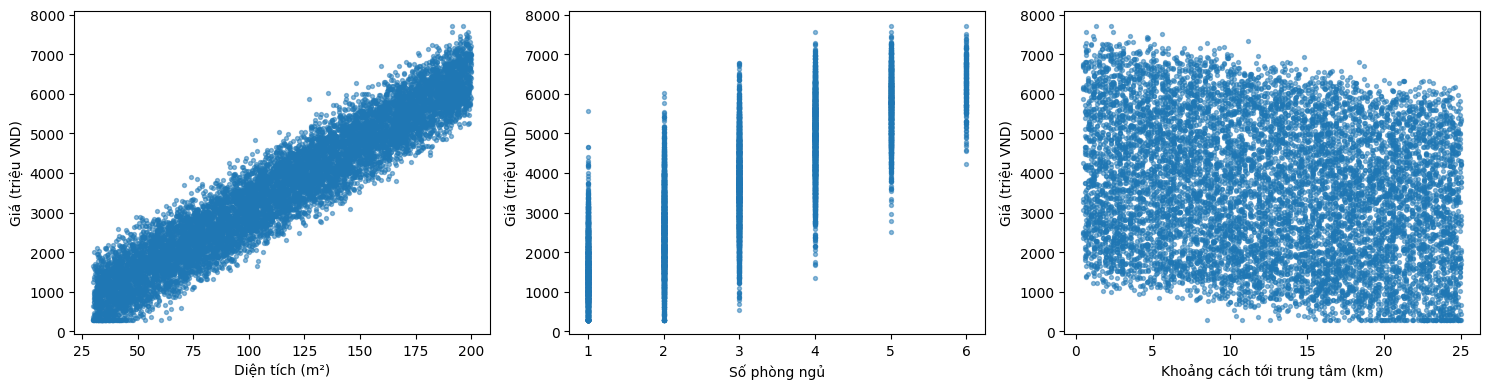

In [3]:
# Quan hệ giữa từng đặc trưng và giá nhà
features = ['area', 'bedrooms', 'distance']                                  # tên cột đặc trưng
labels = ['Diện tích (m²)', 'Số phòng ngủ', 'Khoảng cách tới trung tâm (km)']  # nhãn trục x
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature, label in zip(axes, features, labels):
    ax.scatter(df[feature], df['price'], s=8, alpha=0.5)
    ax.set_xlabel(label)
    ax.set_ylabel('Giá (triệu VND)')
plt.tight_layout()
plt.show()

**Giải thích:** mỗi điểm là một căn nhà.

- Đồ thị 1: các điểm đi lên rõ rệt, nhà càng rộng càng đắt.
- Đồ thị 2: số phòng ngủ là số nguyên nên điểm xếp thành cột; nhiều phòng thì giá cao hơn.
- Đồ thị 3: các điểm hơi đi xuống, càng xa trung tâm giá càng giảm nhưng mức ảnh hưởng yếu hơn.

In [4]:
# Hệ số tương quan giữa các biến
df.corr().round(3).rename(index=column_names, columns=column_names)

,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
Diện tích (m²),1.000,0.851,0.006,0.952
Số phòng ngủ,0.851,1.000,0.018,0.839
Khoảng cách (km),0.006,0.018,1.000,-0.237
Giá (triệu VND),0.952,0.839,-0.237,1.000


**Nhận xét:** giá nhà **tăng** theo diện tích và số phòng ngủ, **giảm** khi xa trung tâm.
Diện tích và số phòng ngủ tương quan khá mạnh với nhau (nhà rộng thường nhiều phòng hơn).

## 2. Chia tập huấn luyện / kiểm tra

In [5]:
from sklearn.model_selection import train_test_split

X = df[features].values   # ma trận đặc trưng, mỗi hàng là một mẫu
y = df['price'].values    # giá nhà

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Tập huấn luyện:', X_train.shape, ' Tập kiểm tra:', X_test.shape)

Tập huấn luyện: (8000, 3)  Tập kiểm tra: (2000, 3)


**Giải thích:**

- `X` có 3 cột (3 đặc trưng), `y` là giá nhà.
- `test_size=0.2`: 20% dữ liệu (2000 căn) để **kiểm tra**, 80% (8000 căn) để **huấn luyện**. Mô hình không được thấy tập kiểm tra khi học, nhờ đó ta đánh giá được khả năng dự đoán trên dữ liệu mới.
- `random_state=42`: cố định cách chia ngẫu nhiên để mỗi lần chạy đều cho cùng kết quả.

## 3. Nghiệm theo công thức (Normal Equation)

$$\bar{\mathbf{w}} = (\bar{\mathbf{X}}^T \bar{\mathbf{X}})^{\dagger} \bar{\mathbf{X}}^T \mathbf{y}$$

trong đó $\bar{\mathbf{X}}$ là $\mathbf{X}$ được thêm cột toàn số 1 ở đầu.

In [6]:
# Tạo ma trận Xbar (thêm cột 1 vào trước ma trận X)
ones = np.ones((X_train.shape[0], 1))
Xbar = np.concatenate((ones, X_train), axis=1)

# Giải OLS trực tiếp, tránh lập ma trận Gram làm tăng điều kiện số
w = np.linalg.lstsq(Xbar, y_train, rcond=None)[0]

print('w0 (hệ số chệch)   = %.4f' % w[0])
print('w1 (diện tích)     = %.4f' % w[1])
print('w2 (số phòng ngủ)  = %.4f' % w[2])
print('w3 (khoảng cách)   = %.4f' % w[3])

w0 (hệ số chệch)   = 505.2032
w1 (diện tích)     = 29.9836
w2 (số phòng ngủ)  = 144.8923
w3 (khoảng cách)   = -59.4633


**Ý nghĩa các hệ số** (dữ liệu được sinh với $w_0=500,\ w_1=30,\ w_2=150,\ w_3=-60$):
- $w_1$: mỗi m² tăng thêm làm giá tăng khoảng $w_1$ triệu.
- $w_2$: mỗi phòng ngủ thêm làm giá tăng khoảng $w_2$ triệu.
- $w_3 < 0$: mỗi km xa trung tâm hơn làm giá giảm khoảng $|w_3|$ triệu.

## 4. Sử dụng thư viện scikit-learn

In [7]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print('Kết quả từ scikit-learn:')
print('  w0 =', round(model.intercept_, 4))
print('  w1, w2, w3 =', np.round(model.coef_, 4))
print('Kết quả tính thủ công:')
print('  w0 =', round(w[0], 4))
print('  w1, w2, w3 =', np.round(w[1:], 4))

Kết quả từ scikit-learn:
  w0 = 505.2032
  w1, w2, w3 = [ 29.9836 144.8923 -59.4633]
Kết quả tính thủ công:
  w0 = 505.2032
  w1, w2, w3 = [ 29.9836 144.8923 -59.4633]


**Giải thích:** `model.intercept_` là $w_0$, `model.coef_` là $[w_1, w_2, w_3]$.
Kết quả của scikit-learn **trùng khớp** với nghiệm tính thủ công ở mục 3, vì `LinearRegression` cũng giải bài toán bình phương tối thiểu.

## 5. Giải bằng Gradient Descent

$$\mathbf{w} \leftarrow \mathbf{w} - \frac{\eta}{N} \bar{\mathbf{X}}^T (\bar{\mathbf{X}}\mathbf{w} - \mathbf{y})$$

Các đặc trưng có thang đo rất khác nhau (diện tích ~100, số phòng ~3), nên cần **chuẩn hóa** (standardization) để Gradient Descent hội tụ nhanh:
$x' = \dfrac{x - \mu}{\sigma}$. Sau khi huấn luyện, ta đổi trọng số về thang đo gốc để so sánh.

Gradient Descent: w0 = 505.2802, w1, w2, w3 = [ 29.9764 145.1505 -59.4638]
Normal Equation : w0 = 505.2032, w1, w2, w3 = [ 29.9836 144.8923 -59.4633]


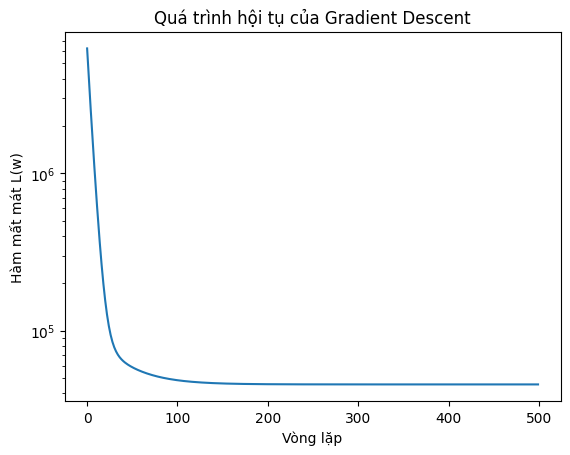

In [8]:
mu = X_train.mean(axis=0)          # trung bình μ của từng đặc trưng
sigma = X_train.std(axis=0)        # độ lệch chuẩn σ của từng đặc trưng
X_scaled = (X_train - mu) / sigma  # dữ liệu đã chuẩn hóa
Xbar_scaled = np.concatenate((np.ones((X_scaled.shape[0], 1)), X_scaled), axis=1)


def loss(w, Xbar, y):
    """Hàm mất mát L(w) = 1/(2N) * ||y - Xbar w||^2."""
    errors = y - Xbar @ w
    return (errors @ errors) / (2 * len(y))


eta = 0.1                                  # tốc độ học η
w_gd = np.zeros(Xbar_scaled.shape[1])      # khởi tạo trọng số bằng 0
loss_history = []                          # giá trị hàm mất mát sau mỗi vòng lặp
for step in range(500):
    grad = Xbar_scaled.T @ (Xbar_scaled @ w_gd - y_train) / len(y_train)   # gradient
    w_gd = w_gd - eta * grad
    loss_history.append(loss(w_gd, Xbar_scaled, y_train))

# Đổi trọng số về thang đo gốc
w_original = w_gd[1:] / sigma
w0_original = w_gd[0] - np.sum(w_gd[1:] * mu / sigma)
print('Gradient Descent: w0 = %.4f, w1, w2, w3 =' % w0_original, np.round(w_original, 4))
print('Normal Equation : w0 = %.4f, w1, w2, w3 =' % w[0], np.round(w[1:], 4))

plt.plot(loss_history)
plt.xlabel('Vòng lặp')
plt.ylabel('Hàm mất mát L(w)')
plt.yscale('log')
plt.title('Quá trình hội tụ của Gradient Descent')
plt.show()

**Giải thích:**

- Mỗi vòng lặp, trọng số được cập nhật ngược hướng gradient với tốc độ học $\eta = 0.1$.
- Đồ thị (trục tung thang log) cho thấy hàm mất mát **giảm nhanh** rồi đi ngang, tức thuật toán đã hội tụ.
- Sau 500 vòng lặp, nghiệm của Gradient Descent rất gần nghiệm của Normal Equation; chênh lệch nhỏ còn lại sẽ giảm nếu chạy thêm vòng lặp.

## 6. Đánh giá mô hình trên tập kiểm tra

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)     # giá dự đoán trên tập kiểm tra
mse = mean_squared_error(y_test, y_pred)

print('MAE  = %.2f triệu' % mean_absolute_error(y_test, y_pred))
print('MSE  = %.2f' % mse)
print('RMSE = %.2f triệu' % np.sqrt(mse))
print('R^2  = %.4f' % r2_score(y_test, y_pred))
print('R^2 trên tập huấn luyện = %.4f' % model.score(X_train, y_train))

MAE  = 241.11 triệu
MSE  = 91237.24
RMSE = 302.06 triệu
R^2  = 0.9685
R^2 trên tập huấn luyện = 0.9690


- **MAE ≈ 241 triệu:** trung bình mỗi dự đoán lệch khoảng 241 triệu, tức khoảng 6.7% so với giá trung bình (~3593 triệu).
- **RMSE ≈ 302 triệu:** lớn hơn MAE một chút vì RMSE phạt nặng các sai số lớn; giá trị này xấp xỉ độ lệch chuẩn của nhiễu (300 triệu) dùng khi sinh dữ liệu.
- **MSE** có đơn vị triệu², khó diễn giải trực tiếp nên thường dùng RMSE.
- **$R^2$ ≈ 0.9685:** mô hình giải thích được khoảng 97% sự biến thiên của giá nhà.
- $R^2$ trên tập huấn luyện (0.9690) và tập kiểm tra (0.9685) gần như bằng nhau: mô hình **không bị quá khớp**.

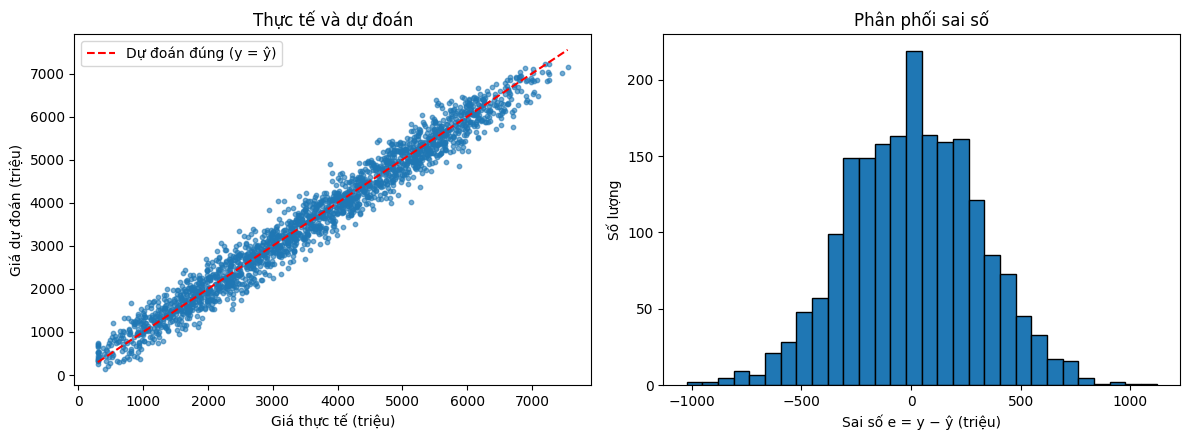

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Giá thực tế và giá dự đoán
axes[0].scatter(y_test, y_pred, s=10, alpha=0.6)
limits = [y_test.min(), y_test.max()]
axes[0].plot(limits, limits, 'r--', label='Dự đoán đúng (y = ŷ)')
axes[0].set_xlabel('Giá thực tế (triệu)')
axes[0].set_ylabel('Giá dự đoán (triệu)')
axes[0].set_title('Thực tế và dự đoán')
axes[0].legend()

# Phân phối sai số
axes[1].hist(y_test - y_pred, bins=30, edgecolor='k')
axes[1].set_xlabel('Sai số e = y − ŷ (triệu)')
axes[1].set_ylabel('Số lượng')
axes[1].set_title('Phân phối sai số')
plt.tight_layout()
plt.show()

**Giải thích:**

- Hình trái: các điểm nằm sát đường đỏ $y = \hat{y}$, tức giá dự đoán gần với giá thực tế.
- Hình phải: sai số tập trung quanh 0, trải khá đều về hai phía, cho thấy mô hình không dự đoán lệch hẳn về một phía; phần sai số còn lại chủ yếu là nhiễu ngẫu nhiên.

## 7. Dự đoán giá cho căn nhà mới

In [11]:
new_houses = pd.DataFrame({        # ba căn nhà mới cần dự đoán giá
    'area':     [60, 100, 150],
    'bedrooms': [2, 3, 4],
    'distance': [3, 10, 20],
})
new_houses['price'] = np.round(model.predict(new_houses.values), 1)
new_houses.rename(columns=column_names)

,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
0,60,2,3,2415.6
1,100,3,10,3343.6
2,150,4,20,4393.0


**Giải thích:** ba căn nhà mới có diện tích, số phòng và khoảng cách khác nhau.
Căn 150 m², 4 phòng có giá dự đoán cao nhất dù ở xa trung tâm (20 km), vì diện tích là yếu tố ảnh hưởng mạnh nhất tới giá.

## 8. Hồi quy Ridge và Lasso

Diện tích và số phòng ngủ tương quan mạnh (đa cộng tuyến). Ta so sánh hệ số của 3 mô hình.

In [12]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(X_train, y_train)
lasso = make_pipeline(StandardScaler(), Lasso(alpha=10.0)).fit(X_train, y_train)

def original_coefficients(pipeline):
    """Đổi hệ số trên dữ liệu chuẩn hóa về đơn vị gốc: m², phòng và km."""
    scaler, regressor = pipeline[0], pipeline[-1]
    weights = regressor.coef_ / scaler.scale_
    intercept = regressor.intercept_ - scaler.mean_ @ weights
    return np.r_[intercept, weights]

coef_table = pd.DataFrame({
    'Tuyến tính': np.r_[model.intercept_, model.coef_],
    'Ridge': original_coefficients(ridge),
    'Lasso': original_coefficients(lasso),
}, index=['w0', 'w1 (diện tích)', 'w2 (số phòng)', 'w3 (khoảng cách)']).round(3)
print(coef_table)
for name, fitted in [('Tuyến tính', model), ('Ridge', ridge), ('Lasso', lasso)]:
    pred = fitted.predict(X_test)
    print('%-10s: RMSE = %.2f, R^2 = %.4f' % (
        name, np.sqrt(mean_squared_error(y_test, pred)), r2_score(y_test, pred)))


                  Tuyến tính    Ridge    Lasso
w0                   505.203  507.894  511.009
w1 (diện tích)        29.984   29.864   29.886
w2 (số phòng)        144.892  148.343  140.421
w3 (khoảng cách)     -59.463  -59.395  -58.021
Tuyến tính: RMSE = 302.06, R^2 = 0.9685
Ridge     : RMSE = 302.05, R^2 = 0.9685
Lasso     : RMSE = 302.21, R^2 = 0.9685


**Giải thích:** Ridge/Lasso học trên đặc trưng chuẩn hóa; bảng đổi hệ số về thang gốc để diễn giải. Điều chuẩn co hệ số trong không gian chuẩn hóa, nhưng từng hệ số sau đổi thang có thể tăng hoặc giảm do các đặc trưng tương quan. Với 8000 mẫu, 3 đặc trưng, OLS đã ổn định; mức điều chuẩn phải chọn bằng CV, không chọn theo bảng test này.

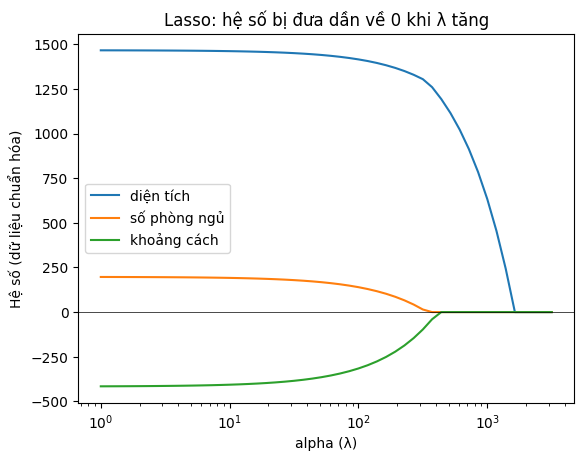

diện tích: hệ số = 0 khi λ ≥ 1638
số phòng ngủ: hệ số = 0 khi λ ≥ 373
khoảng cách: hệ số = 0 khi λ ≥ 439


In [13]:
# Ảnh hưởng của lambda (alpha) lên hệ số Lasso – trên dữ liệu đã chuẩn hóa
from sklearn.preprocessing import StandardScaler
X_train_scaled = StandardScaler().fit_transform(X_train)

alphas = np.logspace(0, 3.5, 50)   # các giá trị λ từ 1 đến khoảng 3162
coefs = np.array([Lasso(alpha=a).fit(X_train_scaled, y_train).coef_ for a in alphas])

for j, label in enumerate(['diện tích', 'số phòng ngủ', 'khoảng cách']):
    plt.plot(alphas, coefs[:, j], label=label)
plt.xscale('log')
plt.xlabel('alpha (λ)')
plt.ylabel('Hệ số (dữ liệu chuẩn hóa)')
plt.title('Lasso: hệ số bị đưa dần về 0 khi λ tăng')
plt.axhline(0, color='k', lw=0.5)
plt.legend()
plt.show()

# λ nhỏ nhất làm mỗi hệ số bằng 0
for j, label in enumerate(['diện tích', 'số phòng ngủ', 'khoảng cách']):
    zero = alphas[coefs[:, j] == 0]
    print(f'{label}: hệ số = 0 khi λ ≥ {zero.min():.0f}' if zero.size else f'{label}: chưa về 0')

**Giải thích:** dữ liệu được chuẩn hóa để so sánh công bằng hệ số giữa các đặc trưng.

- Khi $\lambda$ nhỏ, hệ số gần với hồi quy tuyến tính thông thường.
- Khi $\lambda$ tăng, hệ số của **số phòng ngủ** (khoảng $\lambda \approx 370$) và **khoảng cách** (khoảng $\lambda \approx 440$) về đúng 0 trước: Lasso loại bỏ các đặc trưng kém quan trọng.
- **Diện tích** là đặc trưng quan trọng nhất nên bị đưa về 0 sau cùng (khi $\lambda \approx 1600$).

## 9. Quá khớp với hồi quy đa thức (bài giảng mục 3.2.1)

Chỉ dùng **20 căn nhà** chọn ngẫu nhiên từ tập train, tách biệt với tập test để huấn luyện, một đặc trưng là diện tích. So sánh đa thức bậc 1, bậc 10 và bậc 10 có điều chuẩn Ridge. `PolynomialFeatures(degree)` tạo các đặc trưng $x, x^2, \dots, x^p$. Diện tích được **chuẩn hóa trước khi lũy thừa**: nếu lũy thừa trực tiếp diện tích (tới $200^{10} \approx 10^{23}$), các cột gần như trùng nhau và nghiệm bậc 10 thay đổi theo phiên bản thư viện.

In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

X_area = df[['area']].values                     # chỉ dùng đặc trưng diện tích
X_area_train, X_area_test, y_area_train, y_area_test = train_test_split(
    X_area, y, test_size=0.2, random_state=42)
small_idx = np.random.RandomState(0).choice(len(X_area_train), 20, replace=False)
X_small, y_small = X_area_train[small_idx], y_area_train[small_idx]   # chỉ lấy từ tập train

poly_models = {
    'Bậc 1': make_pipeline(StandardScaler(), PolynomialFeatures(1, include_bias=False), StandardScaler(), LinearRegression()),
    'Bậc 10': make_pipeline(StandardScaler(), PolynomialFeatures(10, include_bias=False), StandardScaler(), LinearRegression()),
    'Bậc 10 + Ridge': make_pipeline(StandardScaler(), PolynomialFeatures(10, include_bias=False), StandardScaler(), Ridge(alpha=1.0)),
}
for name, poly_model in poly_models.items():
    poly_model.fit(X_small, y_small)
    rmse_train = np.sqrt(mean_squared_error(y_small, poly_model.predict(X_small)))
    rmse_test = np.sqrt(mean_squared_error(y_area_test, poly_model.predict(X_area_test)))
    largest = np.abs(poly_model[-1].coef_).max()   # hệ số có độ lớn lớn nhất
    print('%-15s RMSE huấn luyện = %5.0f, RMSE kiểm tra = %5.0f, |w| lớn nhất = %.1e'
          % (name, rmse_train, rmse_test, largest))

Bậc 1           RMSE huấn luyện =   369, RMSE kiểm tra =   555, |w| lớn nhất = 1.5e+03
Bậc 10          RMSE huấn luyện =   309, RMSE kiểm tra =   944, |w| lớn nhất = 2.8e+05
Bậc 10 + Ridge  RMSE huấn luyện =   379, RMSE kiểm tra =   596, |w| lớn nhất = 1.1e+03


**Giải thích:**

- Bậc 10 có sai số huấn luyện nhỏ nhất nhưng sai số kiểm tra lớn hơn rõ rệt so với bậc 1: mô hình **quá khớp**, uốn lượn để đi qua 20 điểm huấn luyện.
- Hệ số của mô hình bậc 10 có độ lớn hàng trăm nghìn, trái dấu nhau để triệt tiêu, trong khi hệ số của bậc 1 chỉ cỡ $10^3$: dấu hiệu điển hình của quá khớp.
- Cùng bậc 10 nhưng có Ridge, hệ số bị kìm lại (cỡ $10^3$) và sai số kiểm tra trở về gần mức của bậc 1.

## 10. Lasso loại bỏ đặc trưng nhiễu (bài giảng mục 3.2.4 d)

Thêm **5 đặc trưng nhiễu** (số ngẫu nhiên, không liên quan đến giá) và chỉ dùng **30 căn nhà** để huấn luyện, tình huống dễ quá khớp.

In [15]:
noisy_df = df.copy()
rng = np.random.RandomState(42)
for k in range(1, 6):
    noisy_df[f'noise_{k}'] = rng.normal(size=len(noisy_df))   # đặc trưng nhiễu, không liên quan tới giá

noisy_columns = features + [f'noise_{k}' for k in range(1, 6)]
X_noisy = noisy_df[noisy_columns].values
X_noisy_train, X_noisy_test, y_noisy_train, y_noisy_test = train_test_split(
    X_noisy, y, train_size=30, random_state=0)

for name, reg in [('OLS', LinearRegression()), ('Ridge', Ridge(alpha=1)), ('Lasso', Lasso(alpha=50))]:
    pipeline = make_pipeline(StandardScaler(), reg).fit(X_noisy_train, y_noisy_train)   # chuẩn hóa rồi huấn luyện
    rmse = np.sqrt(mean_squared_error(y_noisy_test, pipeline.predict(X_noisy_test)))
    print('%-5s' % name, np.round(pipeline[-1].coef_, 1), 'RMSE kiểm tra = %.1f' % rmse)

OLS   [1386.9  224.2 -484.5   16.9   92.6  -23.7   94.7   34.2] RMSE kiểm tra = 348.6
Ridge [1272.3  309.  -482.2   21.3  101.6  -14.6   85.2   36.3] RMSE kiểm tra = 366.9
Lasso [1390.5  178.2 -406.2    0.    26.7   -0.    54.8   -0. ] RMSE kiểm tra = 338.4


**Giải thích:** 3 hệ số đầu ứng với diện tích, số phòng, khoảng cách; 5 hệ số sau ứng với đặc trưng nhiễu.

- OLS gán hệ số khác 0 cho **tất cả** đặc trưng nhiễu: mô hình học cả nhiễu.
- Ridge chỉ làm co hệ số, không loại bỏ đặc trưng nào.
- Lasso đưa 3/5 đặc trưng nhiễu về **đúng 0** và cho sai số kiểm tra thấp nhất.

## 11. So sánh OLS, Ridge, Lasso, Elastic Net trên dữ liệu chuẩn hóa (bài giảng mục 3.3.1 Bước 5, 3.3.2 c)

Quay lại toàn bộ dữ liệu (8000 căn huấn luyện). Chuẩn hóa bằng `StandardScaler` trong `Pipeline` trước khi điều chuẩn, cùng `alpha = 1`.

In [16]:
from sklearn.linear_model import ElasticNet

regularized_models = {
    'OLS': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0),
    'Elastic Net': ElasticNet(alpha=1.0, l1_ratio=0.5),
}
for name, reg in regularized_models.items():
    pipeline = make_pipeline(StandardScaler(), reg).fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    print('%-11s hệ số = %s, RMSE = %.2f, R^2 = %.4f'
          % (name, np.round(pipeline[-1].coef_, 2), np.sqrt(mean_squared_error(y_test, pred)), r2_score(y_test, pred)))

OLS         hệ số = [1467.06  197.69 -417.05], RMSE = 302.06, R^2 = 0.9685
Ridge       hệ số = [1466.47  198.16 -417.  ], RMSE = 302.05, R^2 = 0.9685
Lasso       hệ số = [1466.93  196.79 -416.03], RMSE = 302.04, R^2 = 0.9685
Elastic Net hệ số = [ 801.18  507.95 -278.47], RMSE = 545.35, R^2 = 0.8974


**Giải thích:**

- Với 8000 mẫu và chỉ 3 đặc trưng, OLS không bị quá khớp nên Ridge và Lasso không cải thiện thêm.
- Elastic Net với `alpha=1` kém hẳn: scikit-learn chia tổng bình phương sai số cho $2N$, nên `alpha=1` là mức phạt quá mạnh, các hệ số bị co nhiều (mô hình **chưa khớp**). Không thể chọn `alpha` tùy ý.

## 12. Chọn siêu tham số bằng kiểm định chéo (bài giảng mục 3.3.2 d)

Dùng `GridSearchCV` bao ngoài cả pipeline gồm scaler và estimator: scaler chỉ fit trên phần huấn luyện của từng fold. Đặt `RidgeCV`/`LassoCV`/`ElasticNetCV` sau scaler không đạt điều này vì chúng chia fold bên trong. Chọn cấu hình theo RMSE CV; điểm test chỉ báo cáo cho các quy trình cố định, không dùng để chọn mô hình.

In [17]:
from sklearn.model_selection import GridSearchCV, KFold

alphas = np.logspace(-3, 3, 13)   # lưới cường độ điều chuẩn: 0.001 ... 1000
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_models = {
    'Ridge': (Ridge(), {'ridge__alpha': alphas}),
    'Lasso': (Lasso(max_iter=10000), {'lasso__alpha': alphas}),
    'Elastic Net': (ElasticNet(max_iter=10000),
                    {'elasticnet__alpha': alphas, 'elasticnet__l1_ratio': [0.1, 0.5, 0.9, 1.0]}),
}
searches = {}                    # lưu mô hình được chọn hoàn toàn từ tập train
for name, (regressor, param_grid) in cv_models.items():
    search = GridSearchCV(make_pipeline(StandardScaler(), regressor), param_grid,
                          cv=cv, scoring='neg_root_mean_squared_error')
    search.fit(X_train, y_train)
    searches[name] = search
    pred = search.predict(X_test)
    print(name, 'tham số =', search.best_params_, 'RMSE CV = %.3f' % (-search.best_score_),
          'RMSE test = %.3f' % np.sqrt(mean_squared_error(y_test, pred)),
          'R2 test = %.4f' % r2_score(y_test, pred))


Ridge tham số = {'ridge__alpha': np.float64(0.31622776601683794)} RMSE CV = 302.057 RMSE test = 302.054 R2 test = 0.9685


Lasso tham số = {'lasso__alpha': np.float64(0.03162277660168379)} RMSE CV = 302.057 RMSE test = 302.055 R2 test = 0.9685


Elastic Net tham số = {'elasticnet__alpha': np.float64(0.03162277660168379), 'elasticnet__l1_ratio': 1.0} RMSE CV = 302.057 RMSE test = 302.055 R2 test = 0.9685


**Giải thích:** đọc `best_params_` và RMSE CV để biết mức điều chuẩn được chọn. Scaler được fit lại trong từng fold nên không dùng thống kê của phần xác thực. Trên bộ dữ liệu nhiều mẫu, ít đặc trưng này, các mô hình có chất lượng gần OLS; không khẳng định mô hình tốt hơn ổn định từ chênh lệch nhỏ trên một tập test.

## 13. Kết luận

- Hồi quy tuyến tính khôi phục khá sát các hệ số thật dùng để sinh dữ liệu.
- Normal Equation, scikit-learn và Gradient Descent cho **cùng một nghiệm**.
- $R^2$ gần 1 cho thấy mô hình tuyến tính giải thích tốt phần lớn biến thiên của giá nhà; phần sai số còn lại là do **nhiễu** trong dữ liệu.
- Khi $\lambda$ tăng, Lasso đưa dần các hệ số kém quan trọng về **0** (lựa chọn đặc trưng).
- Với dữ liệu ít mẫu hoặc nhiều đặc trưng, điều chuẩn giúp giảm quá khớp (mục 9, 10); với dữ liệu nhiều mẫu, ít đặc trưng, OLS là đủ và siêu tham số nên chọn bằng **kiểm định chéo** (mục 11, 12).